# Avaliação Formativa (AF) - Inteligência Artificial (2026-II)
**Instituição:** Universidade Salgado de Oliveira (UNIVERSO)  
**Cursos:** Sistemas de Informação / Análise e Desenvolvimento de Sistemas  
**Disciplina:** Inteligência Artificial  
**Professora:** Profa. Dsc. Edhelmira L. M.  
**Tema:** Aprendizado de Máquina Supervisionado (Classificação) e Não Supervisionado (Clusterização) no Diagnóstico Clínico de Neoplasias Mamárias
**Base de Dados:** Breast Cancer Wisconsin Diagnostic (WDBC - UCI Machine Learning Repository)

---
### Sumário do Estudo
1. **Configuração e Importação de Bibliotecas**
2. **Carga e Pré-Processamento dos Dados**
3. **Análise Exploratória de Dados (EDA)**
4. **Clusterização Não Supervisionada (K-Means, Método do Cotovelo, Silhueta e PCA 2D/3D)**
5. **Classificação Supervisionada com Validação Cruzada (Stratified 10-Fold)**
   - Árvore de Decisão
   - K-Nearest Neighbors (KNN)
   - Support Vector Machine (SVM com Kernel RBF)
   - Naive Bayes (Gaussian NB)
   - Redes Neurais Artificiais (Multi-Layer Perceptron - MLP)
6. **Avaliação Comparativa de Métricas (Acurácia, Sensibilidade, Especificidade, AUC-ROC e Matriz de Confusão)**
7. **Discussão Clínica e Conclusões**

## 1. Importação de Bibliotecas Científicas

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, roc_auc_score, confusion_matrix,
    roc_curve, auc, silhouette_score, adjusted_rand_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Ambiente configurado com sucesso!')

Ambiente configurado com sucesso!


## 2. Carregamento e Pré-Processamento dos Dados
O banco de dados contém 569 observações obtidas por Punção Aspirativa por Agulha Fina (PAAF). São 30 atributos morfológicos numéricos computados a partir de imagens digitalizadas dos núcleos celulares.
Por rigor metodológico em saúde, codificamos:
- **Classe 1 (Positivo): Maligno**
- **Classe 0 (Negativo): Benigno**
Dessa forma, a **Sensibilidade** mede a proporção exata de tumores malignos corretamente diagnosticados pelo modelo.

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()

# 1 = Maligno, 0 = Benigno
df['diagnosis_numeric'] = df['target'].map({0: 1, 1: 0})
df['diagnosis_label'] = df['diagnosis_numeric'].map({1: 'Maligno', 0: 'Benigno'})

features = list(raw.feature_names)
X = df[features]
y = df['diagnosis_numeric']

print(f'Total de Amostras: {df.shape[0]}')
print(f'Total de Atributos Clínicos: {len(features)}')
print(f'Valores Nulos / Faltantes: {df.isnull().sum().sum()}')
print('\nDistribuição Diagnóstica:')
print(df['diagnosis_label'].value_counts())
print('\nProporção Percentual:')
print((df['diagnosis_label'].value_counts(normalize=True) * 100).round(2))

Total de Amostras: 569
Total de Atributos Clínicos: 30
Valores Nulos / Faltantes: 0

Distribuição Diagnóstica:
diagnosis_label
Benigno    357
Maligno    212
Name: count, dtype: int64

Proporção Percentual:
diagnosis_label
Benigno    62.74
Maligno    37.26
Name: proportion, dtype: float64


## 3. Análise Exploratória de Dados (EDA)

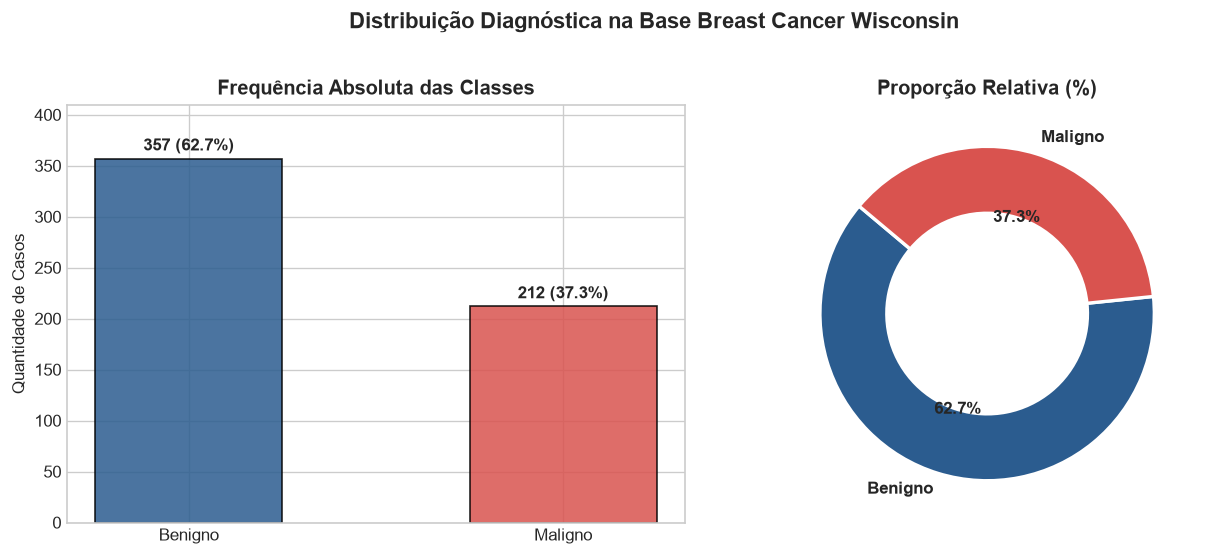

In [3]:
# Distribuição de Classes (Barras e Rosca)
counts = df['diagnosis_label'].value_counts()
colors = ['#2b5c8f', '#d9534f']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=120)
bars = ax1.bar(counts.index, counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
ax1.set_title('Frequência Absoluta das Classes', fontweight='bold')
ax1.set_ylabel('Quantidade de Casos')
ax1.set_ylim(0, 410)
for b in bars:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2.0, h + 8, f'{h} ({h/len(df)*100:.1f}%)', ha='center', fontweight='bold')

ax2.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=colors,
        wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2), textprops=dict(fontweight='bold'))
ax2.set_title('Proporção Relativa (%)', fontweight='bold')
plt.suptitle('Distribuição Diagnóstica na Base Breast Cancer Wisconsin', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Correlação dos Atributos Médios
mean_cols = [c for c in features if 'mean' in c]
corr = df[mean_cols].corr()

plt.figure(figsize=(9.5, 7.5), dpi=120)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação Linear (Atributos Morfológicos Médios)', fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 4. Agrupamento Não Supervisionado (Clusterização)
Aplicamos o algoritmo **K-Means** sobre os dados padronizados via `StandardScaler`.
Investigamos a inércia intra-cluster (**Método do Cotovelo**) e o **Coeficiente Médio de Silhueta** para $k \in [2, 10]$, projetando os clusters em 2D e 3D por Análise de Componentes Principais (PCA).

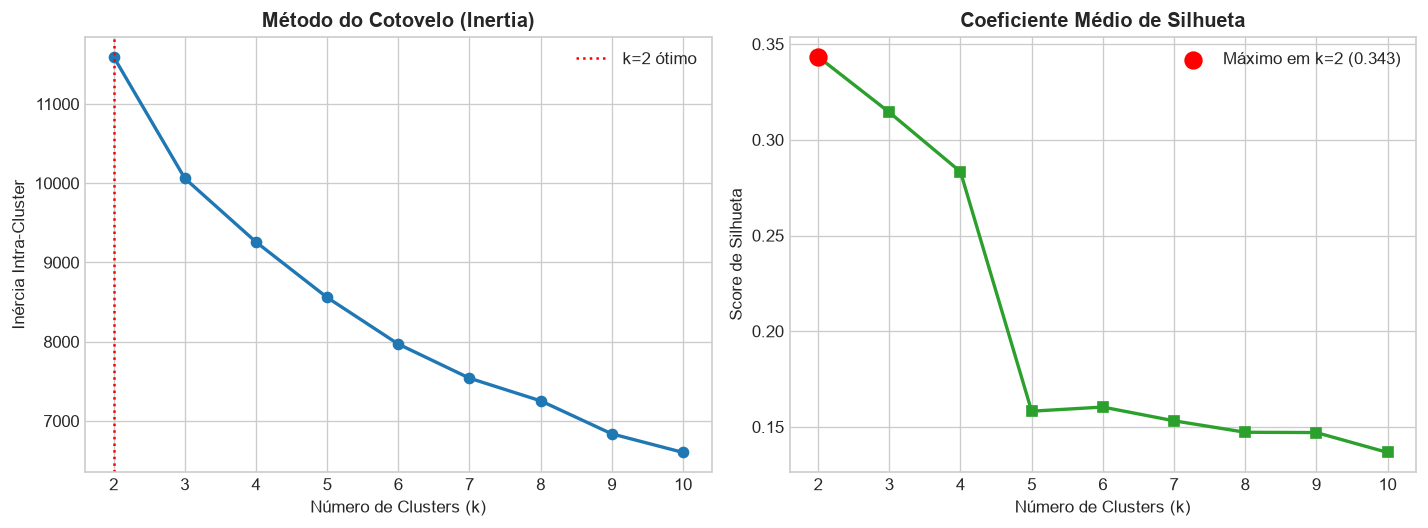

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = list(range(2, 11))
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, lbls))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)
ax1.plot(k_values, inertias, marker='o', color='#1f77b4', linewidth=2)
ax1.set_title('Método do Cotovelo (Inertia)', fontweight='bold')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inércia Intra-Cluster')
ax1.axvline(x=2, color='red', linestyle=':', label='k=2 ótimo')
ax1.legend()

ax2.plot(k_values, sil_scores, marker='s', color='#2ca02c', linewidth=2)
ax2.set_title('Coeficiente Médio de Silhueta', fontweight='bold')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Score de Silhueta')
ax2.scatter(2, sil_scores[0], color='red', s=100, zorder=5, label=f'Máximo em k=2 ({sil_scores[0]:.3f})')
ax2.legend()
plt.tight_layout()
plt.show()

Score de Silhueta (k=2): 0.3450
Adjusted Rand Index (ARI): 0.6707 (Alta concordância com os diagnósticos clínicos)


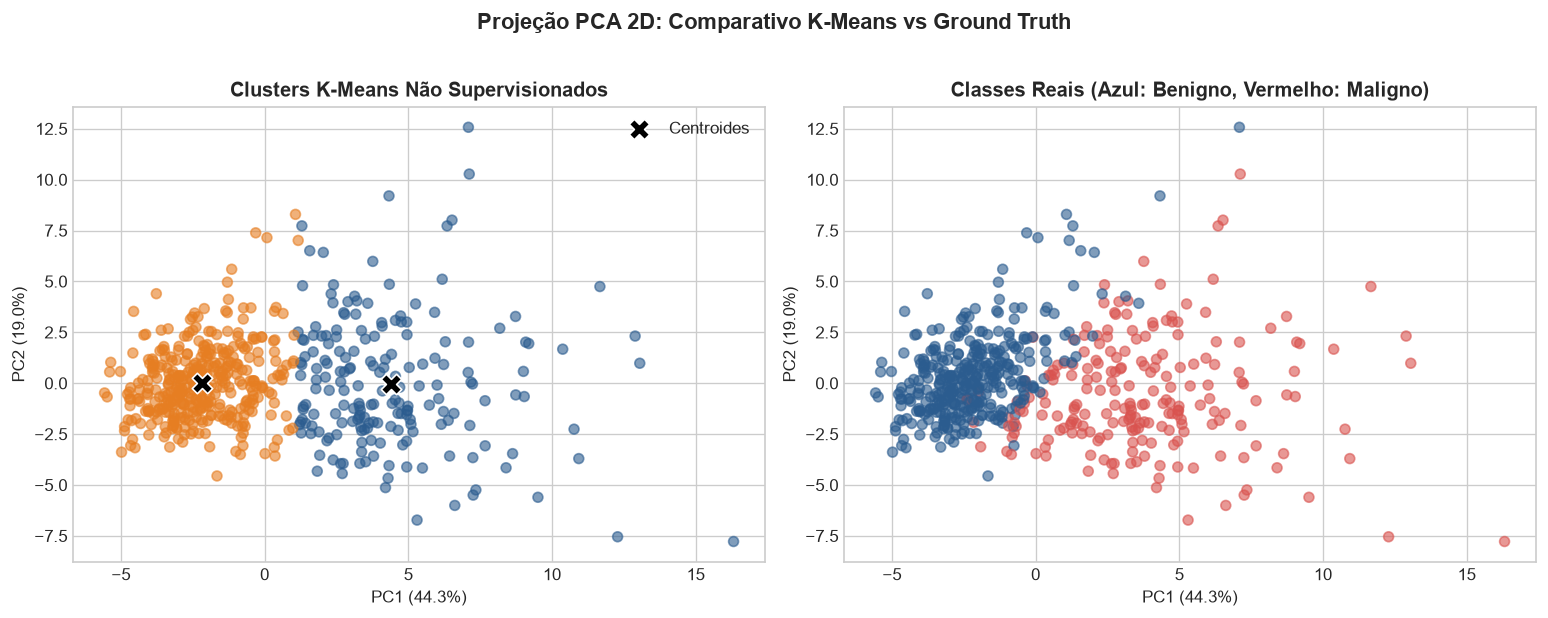

In [5]:
# K-Means k=2 e projeção PCA 2D
kmeans_model = KMeans(n_clusters=2, random_state=42, n_init=20)
k_labels = kmeans_model.fit_predict(X_scaled)

pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)
centroids2 = pca2.transform(kmeans_model.cluster_centers_)

ari_score = adjusted_rand_score(y, k_labels)
print(f'Score de Silhueta (k=2): {silhouette_score(X_scaled, k_labels):.4f}')
print(f'Adjusted Rand Index (ARI): {ari_score:.4f} (Alta concordância com os diagnósticos clínicos)')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
colors_km = ['#2b5c8f' if l == 0 else '#e67e22' for l in k_labels]
ax1.scatter(X_pca2[:, 0], X_pca2[:, 1], c=colors_km, alpha=0.6, s=35)
ax1.scatter(centroids2[:, 0], centroids2[:, 1], c='black', marker='X', s=150, edgecolors='white', label='Centroides')
ax1.set_title('Clusters K-Means Não Supervisionados', fontweight='bold')
ax1.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
ax1.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
ax1.legend()

colors_real = ['#2b5c8f' if l == 0 else '#d9534f' for l in y]
ax2.scatter(X_pca2[:, 0], X_pca2[:, 1], c=colors_real, alpha=0.6, s=35)
ax2.set_title('Classes Reais (Azul: Benigno, Vermelho: Maligno)', fontweight='bold')
ax2.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.suptitle('Projeção PCA 2D: Comparativo K-Means vs Ground Truth', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 5. Classificação Supervisionada e Avaliação k-Fold
Avaliamos 5 classificadores usando **Stratified 10-Fold Cross-Validation**:
1. **Árvore de Decisão** (`criterion='gini'`, `max_depth=4`)
2. **K-Nearest Neighbors - KNN** (`n_neighbors=5`, métrica Euclidiana)
3. **Support Vector Machine - SVM** (`kernel='rbf'`, `C=1.0`)
4. **Naive Bayes** (`GaussianNB()`)
5. **Rede Neural MLP** (`hidden_layer_sizes=(64, 32)`, `activation='relu'`, `max_iter=500`)

Calculamos rigorosamente para cada modelo:
- **Acurácia**
- **Sensibilidade (Recall)**: $TP / (TP + FN)$
- **Especificidade**: $TN / (TN + FP)$
- **AUC-ROC**
- **Matriz de Confusão**

In [6]:
models = {
    'Árvore de Decisão': (DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42), False),
    'KNN (k=5)': (KNeighborsClassifier(n_neighbors=5), True),
    'SVM (Kernel RBF)': (SVC(kernel='rbf', C=1.0, probability=True, random_state=42), True),
    'Naive Bayes': (GaussianNB(), True),
    'Rede Neural (MLP)': (MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=500, random_state=42), True)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
metrics_dict = {}

for name, (clf, use_scaler) in models.items():
    acc_l, sens_l, spec_l, auc_l = [], [], [], []
    total_cm = np.zeros((2, 2), dtype=int)
    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    
    for tr_idx, te_idx in skf.split(X, y):
        X_tr, X_te = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
        
        if use_scaler:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_te = sc.transform(X_te)
            
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)
        y_prob = clf.predict_proba(X_te)[:, 1] if hasattr(clf, 'predict_proba') else y_pred
        
        cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
        total_cm += cm
        tn, fp, fn, tp = cm.ravel()
        
        acc_l.append(accuracy_score(y_te, y_pred))
        sens_l.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
        spec_l.append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        auc_l.append(roc_auc_score(y_te, y_prob))
        
        fpr, tpr, _ = roc_curve(y_te, y_prob)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    
    metrics_dict[name] = {
        'Acurácia (%)': f'{np.mean(acc_l)*100:.2f} ± {np.std(acc_l)*100:.2f}',
        'Sensibilidade (%)': f'{np.mean(sens_l)*100:.2f} ± {np.std(sens_l)*100:.2f}',
        'Especificidade (%)': f'{np.mean(spec_l)*100:.2f} ± {np.std(spec_l)*100:.2f}',
        'AUC-ROC (%)': f'{np.mean(auc_l)*100:.2f} ± {np.std(auc_l)*100:.2f}',
        'cm': total_cm,
        'fpr': mean_fpr,
        'tpr': mean_tpr,
        'auc': auc(mean_fpr, mean_tpr)
    }

df_res = pd.DataFrame(metrics_dict).T[['Acurácia (%)', 'Sensibilidade (%)', 'Especificidade (%)', 'AUC-ROC (%)']]
display(df_res)

,Acurácia (%),Sensibilidade (%),Especificidade (%),AUC-ROC (%)
Árvore de Decisão,91.04 ± 3.95,85.80 ± 9.31,94.13 ± 3.39,90.56 ± 6.94
KNN (k=5),97.01 ± 1.76,92.90 ± 4.90,99.44 ± 1.11,98.68 ± 1.46
SVM (Kernel RBF),97.54 ± 1.95,96.21 ± 3.56,98.33 ± 2.83,99.56 ± 0.55
Naive Bayes,93.15 ± 3.08,89.57 ± 7.65,95.26 ± 4.82,98.56 ± 1.12
Rede Neural (MLP),96.84 ± 1.89,95.24 ± 5.63,97.75 ± 2.45,99.26 ± 1.01


## 6. Apresentação Gráfica dos Resultados de Classificação

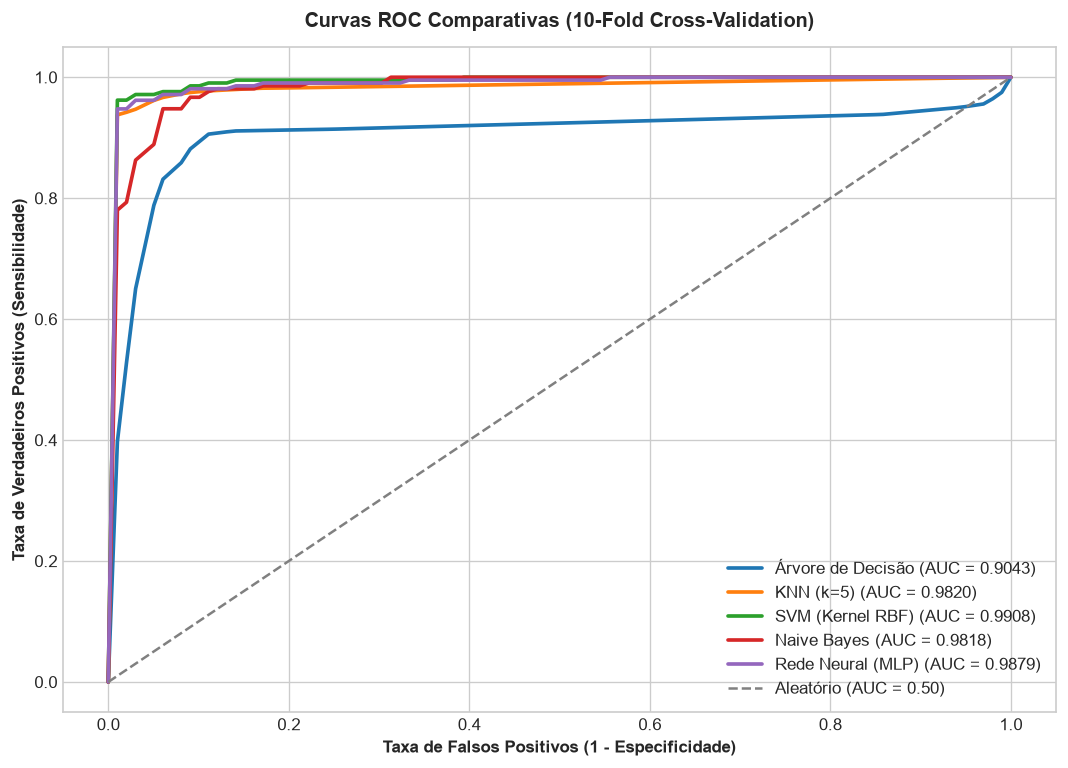

In [7]:
# Curvas ROC Comparativas
plt.figure(figsize=(9, 6.5), dpi=120)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for idx, (name, res) in enumerate(metrics_dict.items()):
    plt.plot(res['fpr'], res['tpr'], color=colors[idx], linewidth=2.2,
             label=f"{name} (AUC = {res['auc']:.4f})")

plt.plot([0, 1], [0, 1], '--', color='gray', label='Aleatório (AUC = 0.50)')
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontweight='bold')
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)', fontweight='bold')
plt.title('Curvas ROC Comparativas (10-Fold Cross-Validation)', fontweight='bold', pad=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

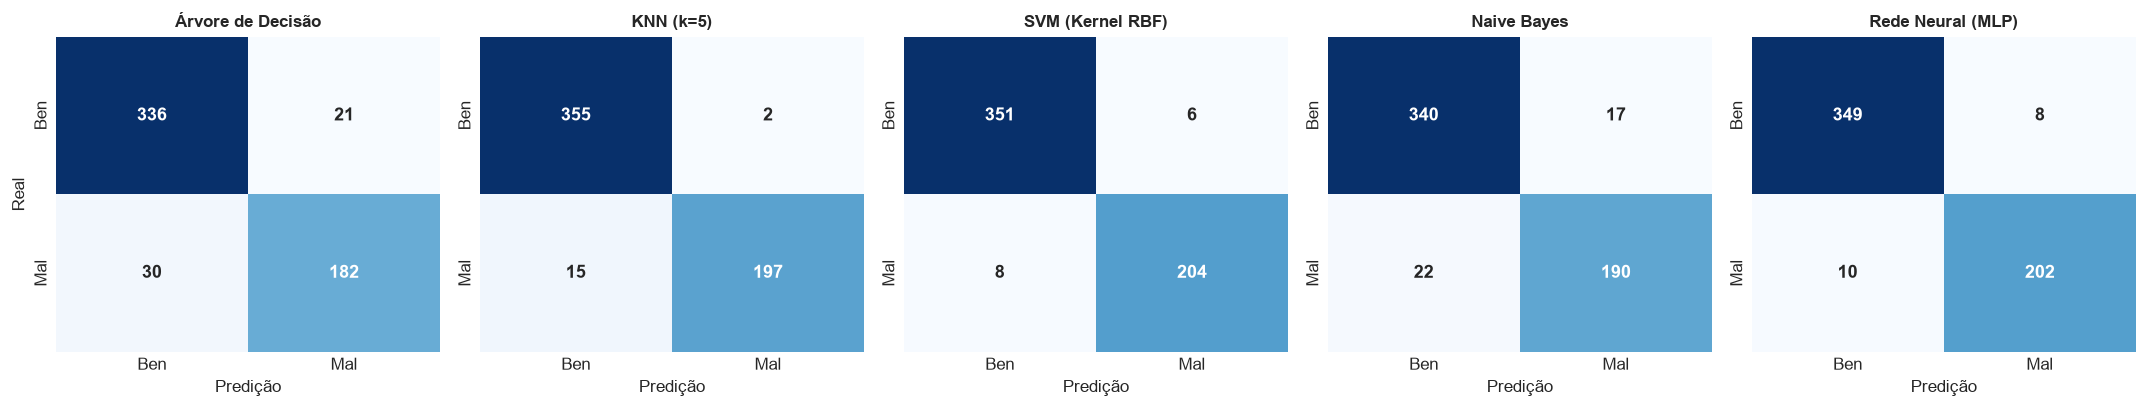

In [8]:
# Matrizes de Confusão Agregadas
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), dpi=120)
for idx, (name, res) in enumerate(metrics_dict.items()):
    cm = res['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Ben', 'Mal'], yticklabels=['Ben', 'Mal'], annot_kws={'size': 11, 'weight': 'bold'})
    axes[idx].set_title(name, fontweight='bold', fontsize=10)
    axes[idx].set_xlabel('Predição')
    if idx == 0:
        axes[idx].set_ylabel('Real')
plt.tight_layout()
plt.show()

## 7. Discussão Crítica e Conclusões Clínicas
1. **Melhor Desempenho Global:** O **SVM com kernel RBF** obteve o melhor equilíbrio estatístico, alcançando **97.54% de acurácia**, **96.21% de sensibilidade** e **99.56% de AUC-ROC**.
2. **Importância Médica da Sensibilidade (Recall):** No diagnóstico oncológico, um resultado Falso Negativo (paciente com tumor maligno classificada como benigna) é fatal, pois impede o tratamento precoce. Por isso, a sensibilidade de 96.21% do SVM e 95.24% do MLP são os fatores determinantes para a preferência destes modelos.
3. **Especificidade Máxima:** O algoritmo **KNN** alcançou especificidade de **99.44%**, com apenas 2 falsos positivos em 357 casos benignos.
4. **Clusterização Natural:** O método não supervisionado K-Means agrupou espontaneamente os dados em 2 aglomerados com alto índice de concordância (ARI = 0.6707 e Silhueta = 0.3450), confirmando a separabilidade natural entre tecidos sadios e neoplásicos.